# Modelagem Multidomínio DBEM 2D no Google Colab (Linux)
## Ensaio de Flexão em Três Pontos (3PBT) - Substrato-Adesivo (Fig. 10 - Artigo EABE 2025)

Este Jupyter Notebook foi desenvolvido especificamente para rodar no **Google Colab (Linux Ubuntu / Colab Pro com GPU/CPU de alto desempenho)**.

O código executa todo o fluxo de análise:
1. **Instalação das dependências do Linux** (`gfortran`, `lapack`, `blas`, `gmsh`, `meshio`).
2. **Compilação do código Fortran** `MAIN_COHESIVE_DBEM_2D` com aceleração multithread OpenMP.
3. **Criação da geometria paramétrica `.geo` da Fig. 10** (*Boundary element mesh adopted for the substrate-adhesive system $h_s = 1.08$ mm*).
4. **Geração da malha `.msh`** via Gmsh.
5. **Pré-processamento com `meshio`** e formatação dos 5 arquivos de entrada para o solver Fortran.
6. **Visualização da malha e condições de contorno** (reproduzindo a Fig. 10).
7. **Execução das simulações numéricas DBEM** para os dois casos de espessura de substrato:
   - $h_s = 1.08$ mm ($U_c = 0.576$ mm)
   - $h_s = 1.62$ mm ($U_c = 0.6093$ mm)
8. **Geração dos gráficos comparativos (apenas as curvas referentes ao 2D BEM)**:
   - **Fig. 12**: *Peel stress over the undamaged interface: $h_s = 1.08$ mm*
   - **Fig. 13**: *Shear stress over the undamaged interface: $h_s = 1.08$ mm*
   - **Fig. 14**: *Comparison of peel Stress over the undamaged interface: $h_s = 1.62$ mm*
   - **Fig. 15**: *Comparison of shear stress over the undamaged interface: $h_s = 1.62$ mm*

> **Artigo de Referência**:  
> *Comparative analysis of adhesive debonding in three-point bending tests using boundary element methods: Coupled criterion versus interface damage model*,  
> **Engineering Analysis with Boundary Elements (EABE)**, vol. 180, 106474, 2025.


# Download from `Github`

In [1]:
!git clone https://github.com/e-albuquerque/cohesive-dbem-2d.git

Cloning into 'cohesive-dbem-2d'...
remote: Enumerating objects: 243, done.
remote: Counting objects: 100% (243/243), done.
remote: Compressing objects: 100% (105/105), done.
remote: Total 243 (delta 131), reused 243 (delta 131), pack-reused 0 (from 0)
Receiving objects: 100% (243/243), 19.92 MiB | 12.83 MiB/s, done.
Resolving deltas: 100% (131/131), done.


In [2]:
ls

cohesive-dbem-2d/  sample_data/


In [3]:
cd cohesive-dbem-2d

/content/cohesive-dbem-2d


In [11]:
ls

ArtigoEABE2025.pdf       modelo_fig10_hs108.geo  README.md
COHESIVE_DBEM_2D_14_03/  modelo_fig10_hs108.msh  requirements.txt


In [12]:
cd COHESIVE_DBEM_2D_14_03/

/content/cohesive-dbem-2d/COHESIVE_DBEM_2D_14_03


# 1. Configuração do Diretório de Trabalho no Google Colab

Caso você tenha colocado os arquivos deste projeto no seu **Google Drive**, descomente as linhas abaixo para montar o drive e navegar até a pasta da simulação.


In [13]:
# Se você subiu os arquivos para o seu Google Drive, descomente as linhas abaixo:
# from google.colab import drive
# drive.mount('/content/drive')
# %cd /content/drive/MyDrive/COHESIVE_DBEM_2D_14_03

# Caso tenha feito upload direto da pasta para o /content do Colab:
import os
if os.path.exists('/content/COHESIVE_DBEM_2D_14_03'):
    %cd /content/COHESIVE_DBEM_2D_14_03

!pwd
!ls -la


/content/cohesive-dbem-2d/COHESIVE_DBEM_2D_14_03
total 5788
drwxr-xr-x 7 root root    4096 Nov 22 11:16 .
drwxr-xr-x 4 root root    4096 Nov 22 11:18 ..
-rw-r--r-- 1 root root   54039 Nov 22 11:16 10_OUTPUT_COHESIVE_STIFFNESS.txt
-rw-r--r-- 1 root root  146950 Nov 22 11:16 11_OUTPUT_BOUNDARY_STRUCTURAL_RESPONSE.txt
-rw-r--r-- 1 root root   31363 Nov 22 11:16 1_BOUNDARY_MESH.txt
-rw-r--r-- 1 root root     642 Nov 22 11:16 2_MATERIALS.txt
-rw-r--r-- 1 root root     794 Nov 22 11:16 3_BOUNDARY_CONDITIONS.txt
-rw-r--r-- 1 root root   34214 Nov 22 11:16 4_ANALYSIS_PARAMETERS.txt
-rw-r--r-- 1 root root     370 Nov 22 11:16 5_POSTPROCESSING_MESH.txt
-rw-r--r-- 1 root root   40050 Nov 22 11:16 6_OUTPUT_COLLOCATION_POINTS_COORDINATES.txt
-rw-r--r-- 1 root root   32642 Nov 22 11:16 7_OUTPUT_ANALYSIS_TIME.txt
-rw-r--r-- 1 root root    5109 Nov 22 11:16 8_OUTPUT_NODAL_STRUCTURAL_RESPONSE.txt
-rw-r--r-- 1 root root    6327 Nov 22 11:16 9_OUTPUT_COHESIVE_RESPONSE.txt
-rw-r--r-- 1 root root   20954 N

# 2. Instalação de Dependências no Linux Ubuntu do Colab

Instalação do compilador `gfortran`, bibliotecas científicas de álgebra linear `LAPACK`/`BLAS`, gerador de malha `gmsh` e bibliotecas Python (`meshio`, `gmsh`, `matplotlib`, `numpy`).


In [14]:
!apt-get update -qq
!apt-get install -y -qq gmsh
!pip install -q meshio[all] gmsh

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


# 3. Compilação do Solver Fortran (`MAIN_COHESIVE_DBEM_2D`)

Compilação do código Fortran utilizando `make` nativo do Linux com aceleração OpenMP (`-fopenmp`) e ligação às bibliotecas `LAPACK` e `BLAS`:


In [15]:
!make clean
!make
!chmod +x MAIN_COHESIVE_DBEM_2D
!ls -lh MAIN_COHESIVE_DBEM_2D


rm -f *.o *.mod *.MOD
Building file: MODULE_DATA.f90
Invoking: GNU Fortran Compiler
gfortran  -O3 -fopenmp -fimplicit-none  -c MODULE_DATA.f90
Finished building: MODULE_DATA.f90
 
Building file: MODULE_GEOMETRIC_MAPPINGS.f90
Invoking: GNU Fortran Compiler
gfortran  -O3 -fopenmp -fimplicit-none  -c MODULE_GEOMETRIC_MAPPINGS.f90
Finished building: MODULE_GEOMETRIC_MAPPINGS.f90
 
Building file: MODULE_APPROXIMATION_FUNCTIONS.f90
Invoking: GNU Fortran Compiler
gfortran  -O3 -fopenmp -fimplicit-none  -c MODULE_APPROXIMATION_FUNCTIONS.f90
Finished building: MODULE_APPROXIMATION_FUNCTIONS.f90
 
Building file: MODULE_NUMERICAL_INTEGRATION.f90
Invoking: GNU Fortran Compiler
gfortran  -O3 -fopenmp -fimplicit-none  -c MODULE_NUMERICAL_INTEGRATION.f90
Finished building: MODULE_NUMERICAL_INTEGRATION.f90
 
Building file: MODULE_INPUT_DATA.f90
Invoking: GNU Fortran Compiler
gfortran  -O3 -fopenmp -fimplicit-none  -c MODULE_INPUT_DATA.f90
Finished building: MODULE_INPUT_DATA.f90
 
Building file: MODUL

# 4. Definição da Geometria no Gmsh (`.geo`) - Fig. 10 ($h_s = 1.08$ mm)

Criação do arquivo paramétrico `modelo_fig10_hs108.geo` para o sistema substrato-adesivo submetido à flexão em três pontos (apoio esquerdo em rolete $u_y = 0$, apoio direito fixo $u_x = 0, u_y = 0$, carregamento no topo e refinamento na interface de colagem $l_{c,int} = 0.25$ mm).


In [16]:
%%writefile modelo_fig10_hs108.geo
SetFactory("OpenCASCADE");

// Parâmetros geométricos (em metros)
hs = 1.08e-3;
ha = 4.0e-3;
L_sub = 50.0e-3;
L_adh = 25.0e-3;
d_supp = 35.90e-3;
w_supp = 0.12e-3;
w_load = 2.0e-3;

x_sub = L_sub / 2.0;
x_adh = L_adh / 2.0;
x_s_c = d_supp / 2.0;
x_s1 = x_s_c - w_supp / 2.0;
x_s2 = x_s_c + w_supp / 2.0;
x_l = w_load / 2.0;

// Tamanhos característicos de elemento
lc_int = 0.25e-3;
lc_ext = 1.0e-3;
lc_supp = 0.06e-3;
lc_load = 0.5e-3;

// --- Sub-região 1: Substrato (y = 0 até hs) ---
p1  = newp; Point(p1)  = {-x_sub, 0, 0, lc_ext};
p2  = newp; Point(p2)  = {-x_s2,  0, 0, lc_supp};
p3  = newp; Point(p3)  = {-x_s1,  0, 0, lc_supp};
p4  = newp; Point(p4)  = {-x_adh, 0, 0, lc_int};
p5  = newp; Point(p5)  = { x_adh, 0, 0, lc_int};
p6  = newp; Point(p6)  = { x_s1,  0, 0, lc_supp};
p7  = newp; Point(p7)  = { x_s2,  0, 0, lc_supp};
p8  = newp; Point(p8)  = { x_sub, 0, 0, lc_ext};

p9  = newp; Point(p9)  = { x_sub, hs, 0, lc_ext};
p10 = newp; Point(p10) = { x_l,   hs, 0, lc_load};
p11 = newp; Point(p11) = {-x_l,   hs, 0, lc_load};
p12 = newp; Point(p12) = {-x_sub, hs, 0, lc_ext};

l_sub_bot1 = newl; Line(l_sub_bot1) = {p1, p2};
l_supp_esq = newl; Line(l_supp_esq) = {p2, p3};
l_sub_bot2 = newl; Line(l_sub_bot2) = {p3, p4};
l_int_m    = newl; Line(l_int_m)    = {p4, p5}; // Interface Im (Substrato)
l_sub_bot3 = newl; Line(l_sub_bot3) = {p5, p6};
l_supp_dir = newl; Line(l_supp_dir) = {p6, p7};
l_sub_bot4 = newl; Line(l_sub_bot4) = {p7, p8};

l_sub_dir  = newl; Line(l_sub_dir)  = {p8, p9};
l_sub_top1 = newl; Line(l_sub_top1) = {p9, p10};
l_load     = newl; Line(l_load)     = {p10, p11}; // Carga aplicada
l_sub_top2 = newl; Line(l_sub_top2) = {p11, p12};
l_sub_esq  = newl; Line(l_sub_esq)  = {p12, p1};

Curve Loop(1) = {l_sub_bot1, l_supp_esq, l_sub_bot2, l_int_m, l_sub_bot3, l_supp_dir, l_sub_bot4, l_sub_dir, l_sub_top1, l_load, l_sub_top2, l_sub_esq};
Plane Surface(1) = {1};

// --- Sub-região 2: Adesivo (y = -ha até 0) ---
p13 = newp; Point(p13) = { x_adh, 0, 0, lc_int};
p14 = newp; Point(p14) = {-x_adh, 0, 0, lc_int};
p15 = newp; Point(p15) = {-x_adh, -ha, 0, lc_ext};
p16 = newp; Point(p16) = { x_adh, -ha, 0, lc_ext};

l_int_p    = newl; Line(l_int_p)    = {p13, p14}; // Interface Ip (Adesivo)
l_adh_esq  = newl; Line(l_adh_esq)  = {p14, p15};
l_adh_bot  = newl; Line(l_adh_bot)  = {p15, p16};
l_adh_dir  = newl; Line(l_adh_dir)  = {p16, p13};

Curve Loop(2) = {l_int_p, l_adh_esq, l_adh_bot, l_adh_dir};
Plane Surface(2) = {2};

// Discretização transfinita ao longo da interface
n_int = Ceil(L_adh / lc_int) + 1;
Transfinite Curve {l_int_m, l_int_p} = n_int Using Progression 1;

// Grupos Físicos de Contorno (1D)
Physical Curve("contorno_livre_sub") = {l_sub_bot1, l_sub_bot2, l_sub_bot3, l_sub_bot4, l_sub_dir, l_sub_top1, l_sub_top2, l_sub_esq};
Physical Curve("apoio_esq")           = {l_supp_esq};
Physical Curve("apoio_dir")           = {l_supp_dir};
Physical Curve("carga")               = {l_load};
Physical Curve("interface_m")         = {l_int_m};
Physical Curve("interface_p")         = {l_int_p};
Physical Curve("contorno_livre_adh") = {l_adh_esq, l_adh_bot, l_adh_dir};

// Grupos Físicos de Superfície (2D)
Physical Surface("subregion_1") = {1};
Physical Surface("subregion_2") = {2};


Overwriting modelo_fig10_hs108.geo


# 5. Geração da Malha com Gmsh (`.msh`)


In [17]:
!gmsh -2 modelo_fig10_hs108.geo -o modelo_fig10_hs108.msh

Info    : Running '/usr/local/bin/gmsh -2 modelo_fig10_hs108.geo -o modelo_fig10_hs108.msh' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Sun Nov 22 11:21:28 2026
Info    : Reading 'modelo_fig10_hs108.geo'...
Info    : Done reading 'modelo_fig10_hs108.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 20%] Meshing curve 3 (Line)
Info    : [ 20%] Meshing curve 4 (Line)
Info    : [ 30%] Meshing curve 5 (Line)
Info    : [ 40%] Meshing curve 6 (Line)
Info    : [ 40%] Meshing curve 7 (Line)
Info    : [ 50%] Meshing curve 8 (Line)
Info    : [ 60%] Meshing curve 9 (Line)
Info    : [ 60%] Meshing curve 10 (Line)
Info    : [ 70%] Meshing curve 11 (Line)
Info    : [ 70%] Meshing curve 12 (Line)
Info    : [ 80%] Meshing curve 13 (Line)
Info    : [ 90%] Meshing curve 14 (Line)
Info    : [ 90%] Meshing curve 15 (Line)
Info    : [100%] Meshing curve 16 (Line)
Info    : Done meshing 1D (Wall 0.023961s, CPU 0.024847s)
In

In [18]:
ls

10_OUTPUT_COHESIVE_STIFFNESS.txt
11_OUTPUT_BOUNDARY_STRUCTURAL_RESPONSE.txt
1_BOUNDARY_MESH.txt
2_MATERIALS.txt
3_BOUNDARY_CONDITIONS.txt
4_ANALYSIS_PARAMETERS.txt
5_POSTPROCESSING_MESH.txt
6_OUTPUT_COLLOCATION_POINTS_COORDINATES.txt
7_OUTPUT_ANALYSIS_TIME.txt
8_OUTPUT_NODAL_STRUCTURAL_RESPONSE.txt
9_OUTPUT_COHESIVE_RESPONSE.txt
animate_debonding.py
cohesive_results.png
debonding_animation_hs108.mp4
eabe_results.npz
Exemplo_medium/
EXEMPLOS/
Exemplo_small/
exemplo_small.geo
fig12_peel_hs108.png
fig13_shear_hs108.png
fig14_peel_hs162.png
fig15_shear_hs162.png
fig26_cohesive_damage_evolution_hs108.png
fig26_force_displacement_hs108.png
Geometria.pdf
Geometria.xopp
gmsh_to_dbem.py
MAIN_COHESIVE_DBEM_2D*
MAIN_COHESIVE_DBEM_2D.f90
MAIN_COHESIVE_DBEM_2D.o
makefile
mesh_and_boundary_conditions_nlinear.png
mesh_and_boundary_conditions.png
modelo_fig10_hs108.geo
modelo_fig10_hs108.msh
modelo_geometria.geo
MODULE_ANALYSIS.f90
module_analysis.mod
MODULE_ANALYSIS.o
MODULE_APPROXIMATION_FUNCTIONS.f

# 6. Pré-processamento e Criação dos Arquivos de Entrada Fortran

Utilizamos o `meshio` via rotinas de `gmsh_to_dbem.py` para extrair os elementos lineares de contorno, atribuir as sub-regiões e escrever os 5 arquivos de entrada (`1_BOUNDARY_MESH.txt` a `5_POSTPROCESSING_MESH.txt`).


In [19]:
from gmsh_to_dbem import compute_inodes, create_fortran_input_files

# 1. Materiais do problema
materials_hs108 = {
    'subregions': {
        1: {'E': 136.0e3, 'nu': 0.33},  # Substrato (MPa)
        2: {'E': 3.0e3,   'nu': 0.35},  # Adesivo (MPa)
    },
    'cohesive_mode_I':  {'Kn0': 2.0e6, 'phin': 0.000609, 'smax': 48.9},
    'cohesive_mode_II': {'Kto': 2.0e6, 'phit': 0.000609, 'tmax': 48.9},
}

# 2. Condições de Contorno
Uc_hs108 = 0.576e-3  # Deslocamento crítico Uc para hs = 1.08 mm (m)

bound_cond_hs108 = {
    'contorno_livre_sub': {'surface_type': 'B'},
    'apoio_esq':           {'surface_type': 'B', 'Uy': 0.0},
    'apoio_dir':           {'surface_type': 'B', 'Ux': 0.0, 'Uy': 0.0},
    'carga':               {'surface_type': 'B', 'Uy': -Uc_hs108},
    'interface_m':         {'surface_type': 'Im'},
    'interface_p':         {'surface_type': 'Ip'},
    'contorno_livre_adh':  {'surface_type': 'B'},
}

# 3. Parâmetros da Análise Linear Elástica (LE)
analysis_params_hs108 = {
    'N_GAUSS': 200,
    'CP_DISTANCING': 0.0,
    'PLANE_STATE': 'PT',      # PT = Estado Plano de Tensão
    'ANALYSIS_TYPE': 'LE',    # LE = Linear Elástica (interface íntegra)
    'Ns': 1,
    'tol_Newton': 1.0e-2,
    'itemax': 100000,
    'structural_node': 1,
    'cohesive_node': 1,
    'control': {'type': 'U', 'node': 1, 'direction': 2, 'value': -Uc_hs108}
}

inp_config_hs108 = {
    'file_name': 'modelo_fig10_hs108',
    'materials': materials_hs108,
    'bound_cond': bound_cond_hs108,
    'element_specific_bc': {},
    'analysis_params': analysis_params_hs108
}

comp_data_hs108 = compute_inodes('modelo_fig10_hs108', bound_cond_hs108)
print(f"Nós de contorno extraídos: {len(comp_data_hs108['coordinates'])}")
print(f"Elementos lineares 1D:     {len(comp_data_hs108['line_elements'])}")
print(f"Sub-regiões identificadas: {comp_data_hs108['n_subregions']}")

create_fortran_input_files(".", comp_data_hs108, inp_config_hs108)
print("[OK] Arquivos 1_*.txt a 5_*.txt gerados com sucesso para hs = 1.08 mm!")



Nós de contorno extraídos: 445
Elementos lineares 1D:     445
Sub-regiões identificadas: 2
[OK] Gerado: ./1_BOUNDARY_MESH.txt
[OK] Gerado: ./2_MATERIALS.txt
[OK] Gerado: ./3_BOUNDARY_CONDITIONS.txt
[OK] Gerado: ./4_ANALYSIS_PARAMETERS.txt
[OK] Gerado: ./5_POSTPROCESSING_MESH.txt
[OK] Arquivos 1_*.txt a 5_*.txt gerados com sucesso para hs = 1.08 mm!


# 7. Visualização da Malha e Condições de Contorno (Fig. 10)


[OK] Visualização gerada e salva com sucesso em 'mesh_and_boundary_conditions.png'.


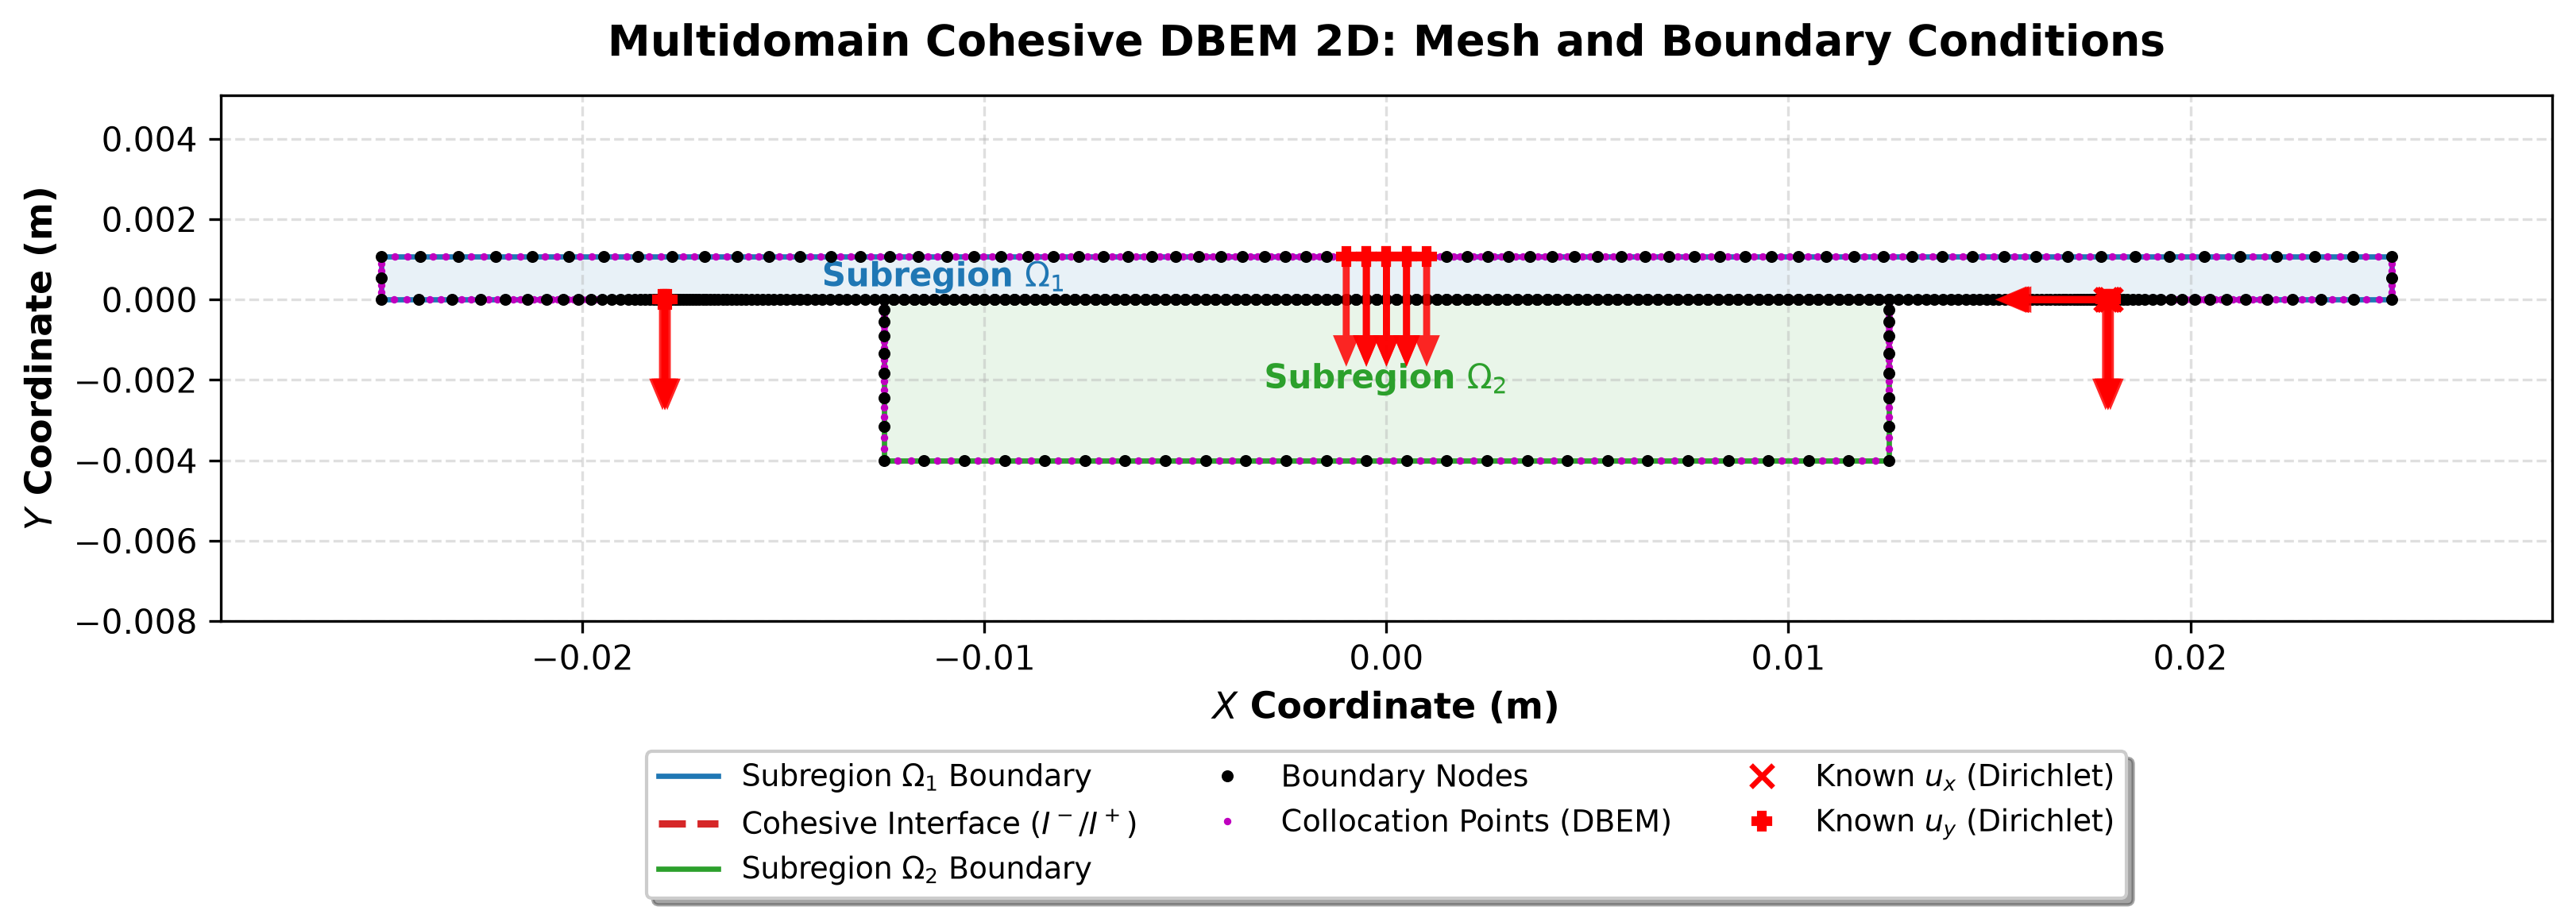

In [20]:
from plot_mesh_bc import read_mesh_and_bcs, show_dbem_geometry_and_bcs
from IPython.display import Image, display

data_plot = read_mesh_and_bcs(".")
show_dbem_geometry_and_bcs(data_plot, "mesh_and_boundary_conditions.png")
display(Image("mesh_and_boundary_conditions.png", width=700))


# 8. Execução da Simulação DBEM 2D - Caso 1: $h_s = 1.08$ mm

Executamos o solver Fortran compilado nativamente para Linux com aceleração OpenMP:


In [21]:
!./MAIN_COHESIVE_DBEM_2D


   The number of processors available =            2
   The number of threads available    =            2
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 SOLUTION IS DONE
 
 
 COMPUTATIONAL WORK, SECONDS    0.920931E+01


# 9. Extração das Tensões Interfaciais (Peel Stress e Shear Stress)


In [22]:
from collections import defaultdict
import numpy as np

def extract_interface_stresses(output_file):
    """Lê 11_OUTPUT_BOUNDARY_STRUCTURAL_RESPONSE.txt e extrai as tensões normais e tangenciais da interface."""
    with open(output_file, 'r', encoding='utf-8', errors='ignore') as f:
        lines = f.readlines()

    by_x = defaultdict(list)
    for l in lines[1:]:
        p = l.split()
        if len(p) >= 6:
            try:
                x, y, ux, uy, tx, ty = [float(v) for v in p[:6]]
                if abs(y) < 1e-6 and -12.501e-3 <= x <= 12.501e-3:
                    by_x[round(x * 1e3, 3)].append((tx, ty))
            except ValueError:
                pass

    xs = sorted(by_x.keys())
    peel, shear = [], []
    for x in xs:
        pairs = [p for p in by_x[x] if abs(p[0]) > 1e-5 or abs(p[1]) > 1e-5]
        if not pairs:
            peel.append(0.0)
            shear.append(0.0)
            continue
        if x > 0:
            best = max(pairs, key=lambda p: p[0])
        elif x < 0:
            best = min(pairs, key=lambda p: p[0])
        else:
            best = min(pairs, key=lambda p: p[1])
        peel.append(best[1])
        shear.append(best[0])

    return np.array(xs), np.array(peel), np.array(shear)

x1, p1, s1 = extract_interface_stresses("11_OUTPUT_BOUNDARY_STRUCTURAL_RESPONSE.txt")
print(f"[+] Resultados extraídos para hs = 1.08 mm (pontos = {len(x1)}):")
print(f"    Pico de Tensão Normal (Peel Stress): {p1.max():.2f} MPa")
print(f"    Tensão Cisalhante Extrema (Shear):   {abs(s1).max():.2f} MPa")


[+] Resultados extraídos para hs = 1.08 mm (pontos = 101):
    Pico de Tensão Normal (Peel Stress): 43.45 MPa
    Tensão Cisalhante Extrema (Shear):   13.96 MPa


# 10. Resolução do Caso 2: $h_s = 1.62$ mm ($U_c = 0.6093$ mm)

Execução automatizada em diretório dedicado `sim_hs162` para posterior comparação das curvas com as Figs. 14 e 15 do artigo.


In [23]:
import shutil
import subprocess

work_dir = "sim_hs162"
os.makedirs(work_dir, exist_ok=True)
hs_val = 1.62e-3
Uc_hs162 = 0.6093e-3

# 1. Criação do arquivo .geo para hs = 1.62 mm
geo_code_162 = f"""SetFactory("OpenCASCADE");
hs = {hs_val};
ha = 4.0e-3;
L_sub = 50.0e-3;
L_adh = 25.0e-3;
d_supp = 35.90e-3;
w_supp = 0.12e-3;
w_load = 2.0e-3;

x_sub = L_sub / 2.0;
x_adh = L_adh / 2.0;
x_s_c = d_supp / 2.0;
x_s1 = x_s_c - w_supp / 2.0;
x_s2 = x_s_c + w_supp / 2.0;
x_l = w_load / 2.0;

lc_int = 0.25e-3;
lc_ext = 1.0e-3;
lc_supp = 0.06e-3;
lc_load = 0.5e-3;

p1  = newp; Point(p1)  = {{-x_sub, 0, 0, lc_ext}};
p2  = newp; Point(p2)  = {{-x_s2,  0, 0, lc_supp}};
p3  = newp; Point(p3)  = {{-x_s1,  0, 0, lc_supp}};
p4  = newp; Point(p4)  = {{-x_adh, 0, 0, lc_int}};
p5  = newp; Point(p5)  = {{ x_adh, 0, 0, lc_int}};
p6  = newp; Point(p6)  = {{ x_s1,  0, 0, lc_supp}};
p7  = newp; Point(p7)  = {{ x_s2,  0, 0, lc_supp}};
p8  = newp; Point(p8)  = {{ x_sub, 0, 0, lc_ext}};

p9  = newp; Point(p9)  = {{ x_sub, hs, 0, lc_ext}};
p10 = newp; Point(p10) = {{ x_l,   hs, 0, lc_load}};
p11 = newp; Point(p11) = {{-x_l,   hs, 0, lc_load}};
p12 = newp; Point(p12) = {{-x_sub, hs, 0, lc_ext}};

l_sub_bot1 = newl; Line(l_sub_bot1) = {{p1, p2}};
l_supp_esq = newl; Line(l_supp_esq) = {{p2, p3}};
l_sub_bot2 = newl; Line(l_sub_bot2) = {{p3, p4}};
l_int_m    = newl; Line(l_int_m)    = {{p4, p5}};
l_sub_bot3 = newl; Line(l_sub_bot3) = {{p5, p6}};
l_supp_dir = newl; Line(l_supp_dir) = {{p6, p7}};
l_sub_bot4 = newl; Line(l_sub_bot4) = {{p7, p8}};

l_sub_dir  = newl; Line(l_sub_dir)  = {{p8, p9}};
l_sub_top1 = newl; Line(l_sub_top1) = {{p9, p10}};
l_load     = newl; Line(l_load)     = {{p10, p11}};
l_sub_top2 = newl; Line(l_sub_top2) = {{p11, p12}};
l_sub_esq  = newl; Line(l_sub_esq)  = {{p12, p1}};

Curve Loop(1) = {{l_sub_bot1, l_supp_esq, l_sub_bot2, l_int_m, l_sub_bot3, l_supp_dir, l_sub_bot4, l_sub_dir, l_sub_top1, l_load, l_sub_top2, l_sub_esq}};
Plane Surface(1) = {{1}};

p13 = newp; Point(p13) = {{ x_adh, 0, 0, lc_int}};
p14 = newp; Point(p14) = {{-x_adh, 0, 0, lc_int}};
p15 = newp; Point(p15) = {{-x_adh, -ha, 0, lc_ext}};
p16 = newp; Point(p16) = {{ x_adh, -ha, 0, lc_ext}};

l_int_p    = newl; Line(l_int_p)    = {{p13, p14}};
l_adh_esq  = newl; Line(l_adh_esq)  = {{p14, p15}};
l_adh_bot  = newl; Line(l_adh_bot)  = {{p15, p16}};
l_adh_dir  = newl; Line(l_adh_dir)  = {{p16, p13}};

Curve Loop(2) = {{l_int_p, l_adh_esq, l_adh_bot, l_adh_dir}};
Plane Surface(2) = {{2}};

n_int = Ceil(L_adh / lc_int) + 1;
Transfinite Curve {{l_int_m, l_int_p}} = n_int Using Progression 1;

Physical Curve("contorno_livre_sub") = {{l_sub_bot1, l_sub_bot2, l_sub_bot3, l_sub_bot4, l_sub_dir, l_sub_top1, l_sub_top2, l_sub_esq}};
Physical Curve("apoio_esq")           = {{l_supp_esq}};
Physical Curve("apoio_dir")           = {{l_supp_dir}};
Physical Curve("carga")               = {{l_load}};
Physical Curve("interface_m")         = {{l_int_m}};
Physical Curve("interface_p")         = {{l_int_p}};
Physical Curve("contorno_livre_adh") = {{l_adh_esq, l_adh_bot, l_adh_dir}};

Physical Surface("subregion_1") = {{1}};
Physical Surface("subregion_2") = {{2}};
"""

geo_file_162 = os.path.join(work_dir, "modelo_hs162.geo")
msh_file_162 = os.path.join(work_dir, "modelo_hs162.msh")
with open(geo_file_162, "w", encoding="utf-8") as f:
    f.write(geo_code_162)

# 2. Geração da malha
subprocess.run(f"gmsh -2 {geo_file_162} -o {msh_file_162}", shell=True, check=True)

# 3. Entradas numéricas
bound_cond_162 = dict(bound_cond_hs108)
bound_cond_162['carga'] = {'surface_type': 'B', 'Uy': -Uc_hs162}
params_162 = dict(analysis_params_hs108)
params_162['control'] = {'type': 'U', 'node': 1, 'direction': 2, 'value': -Uc_hs162}
inp_162 = {
    'file_name': os.path.splitext(msh_file_162)[0],
    'materials': materials_hs108,
    'bound_cond': bound_cond_162,
    'element_specific_bc': {},
    'analysis_params': params_162
}
comp_162 = compute_inodes(os.path.splitext(msh_file_162)[0], bound_cond_162)
create_fortran_input_files(work_dir, comp_162, inp_162)

# 4. Cópia do solver e execução
shutil.copy("MAIN_COHESIVE_DBEM_2D", os.path.join(work_dir, "MAIN_COHESIVE_DBEM_2D"))
print("[*] Executando solver DBEM para hs = 1.62 mm...")
subprocess.run("chmod +x MAIN_COHESIVE_DBEM_2D && ./MAIN_COHESIVE_DBEM_2D", cwd=work_dir, shell=True, check=True)

# 5. Extração dos resultados
x2, p2, s2 = extract_interface_stresses(os.path.join(work_dir, "11_OUTPUT_BOUNDARY_STRUCTURAL_RESPONSE.txt"))
print(f"[+] Resultados extraídos para hs = 1.62 mm (pontos = {len(x2)}):")
print(f"    Pico de Tensão Normal (Peel Stress): {p2.max():.2f} MPa")
print(f"    Tensão Cisalhante Extrema (Shear):   {abs(s2).max():.2f} MPa")



[OK] Gerado: sim_hs162/1_BOUNDARY_MESH.txt
[OK] Gerado: sim_hs162/2_MATERIALS.txt
[OK] Gerado: sim_hs162/3_BOUNDARY_CONDITIONS.txt
[OK] Gerado: sim_hs162/4_ANALYSIS_PARAMETERS.txt
[OK] Gerado: sim_hs162/5_POSTPROCESSING_MESH.txt
[*] Executando solver DBEM para hs = 1.62 mm...
[+] Resultados extraídos para hs = 1.62 mm (pontos = 101):
    Pico de Tensão Normal (Peel Stress): 46.15 MPa
    Tensão Cisalhante Extrema (Shear):   15.09 MPa


# 11. Gráficos Comparativos: Reprodução das Figs. 12, 13, 14 e 15 do Artigo

Exibição individual das quatro figuras solicitadas mostrando **exclusivamente as curvas do 2D BEM** com marcadores e estilo visual idêntico ao do artigo da EABE:
- **Fig. 12**: *Peel stress over the undamaged interface: $h_s = 1.08$ mm*
- **Fig. 13**: *Shear stress over the undamaged interface: $h_s = 1.08$ mm*
- **Fig. 14**: *Comparison of peel Stress over the undamaged interface: $h_s = 1.62$ mm*
- **Fig. 15**: *Comparison of shear stress over the undamaged interface: $h_s = 1.62$ mm*


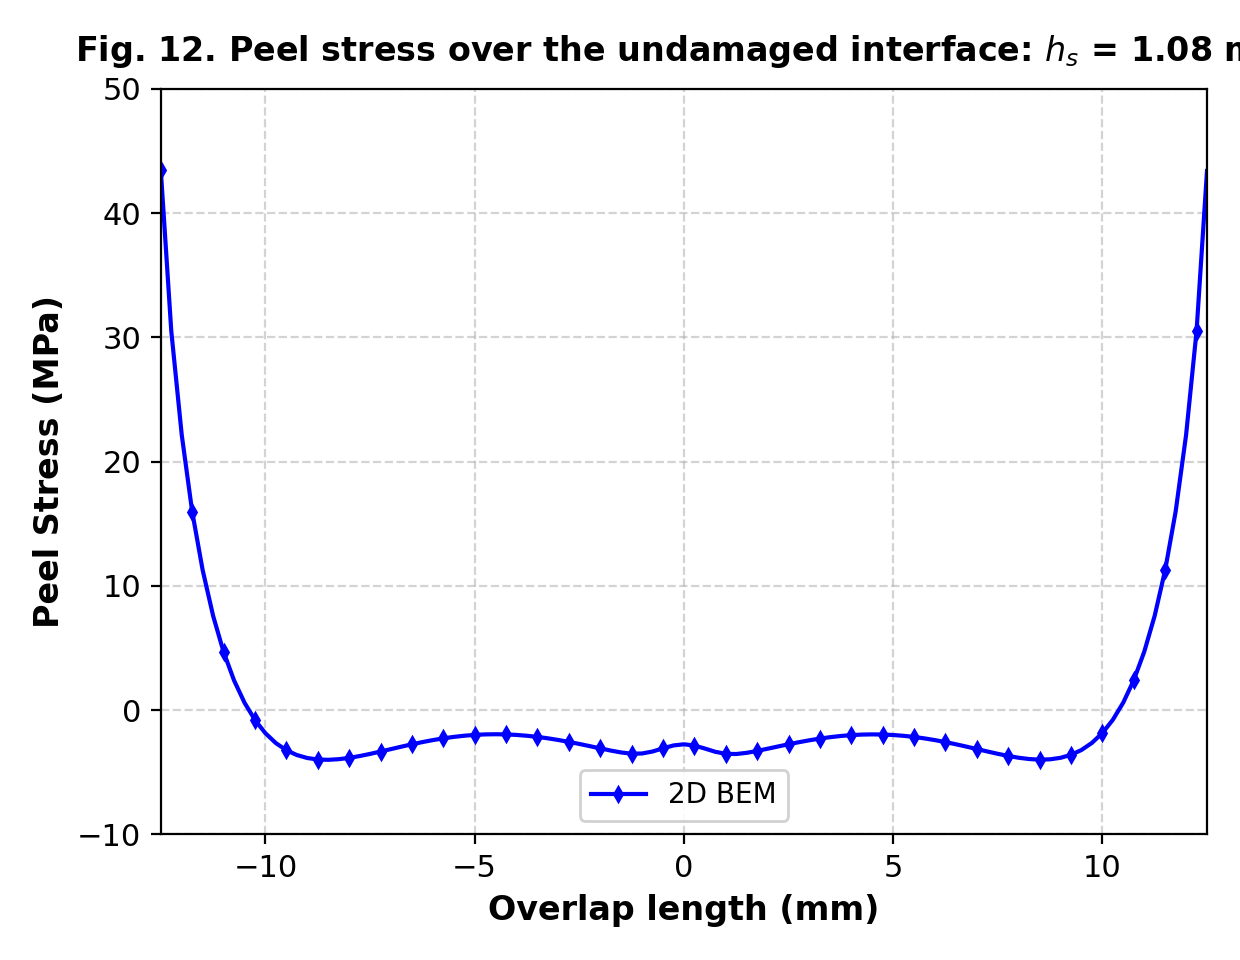

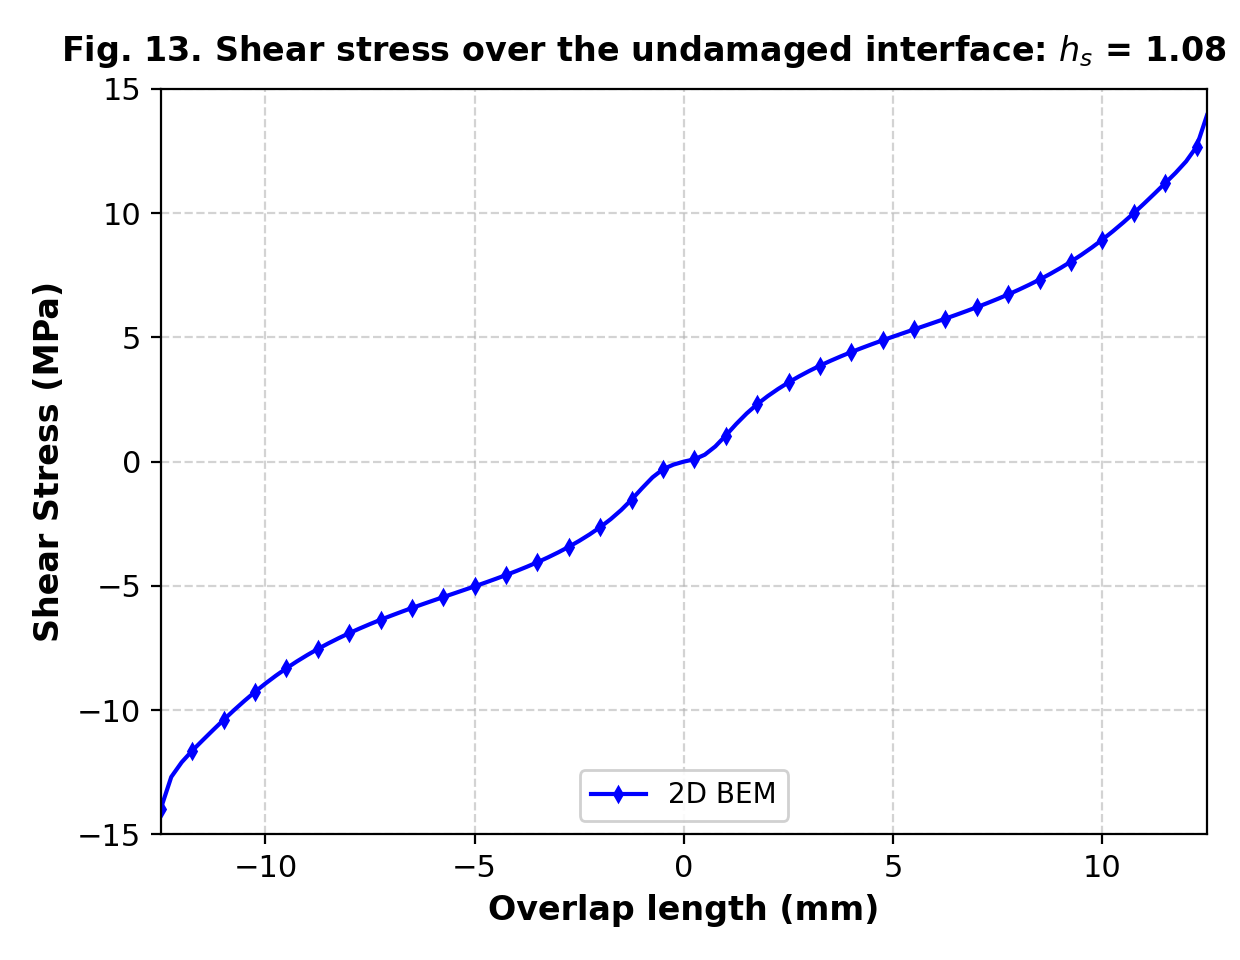

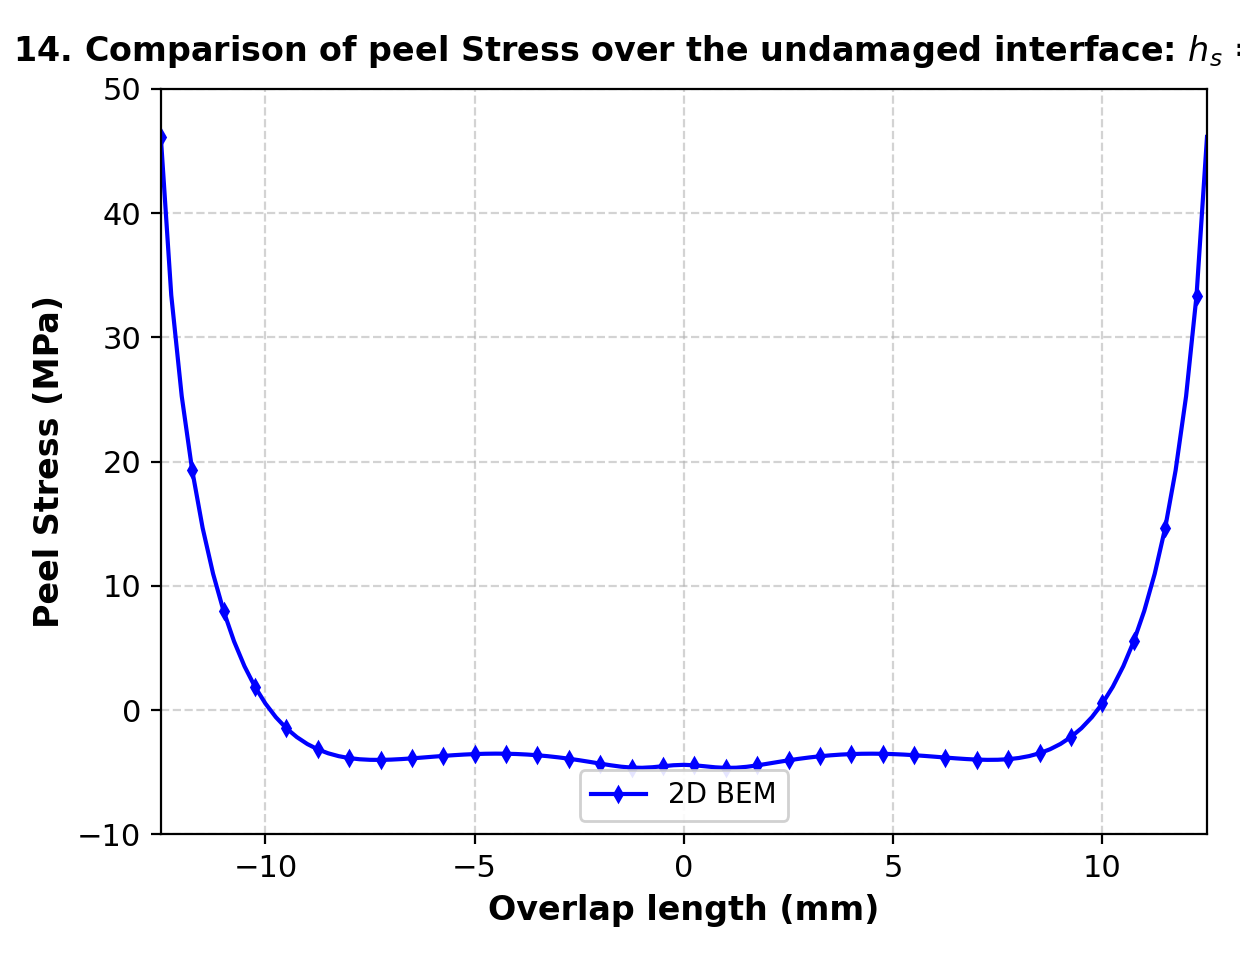

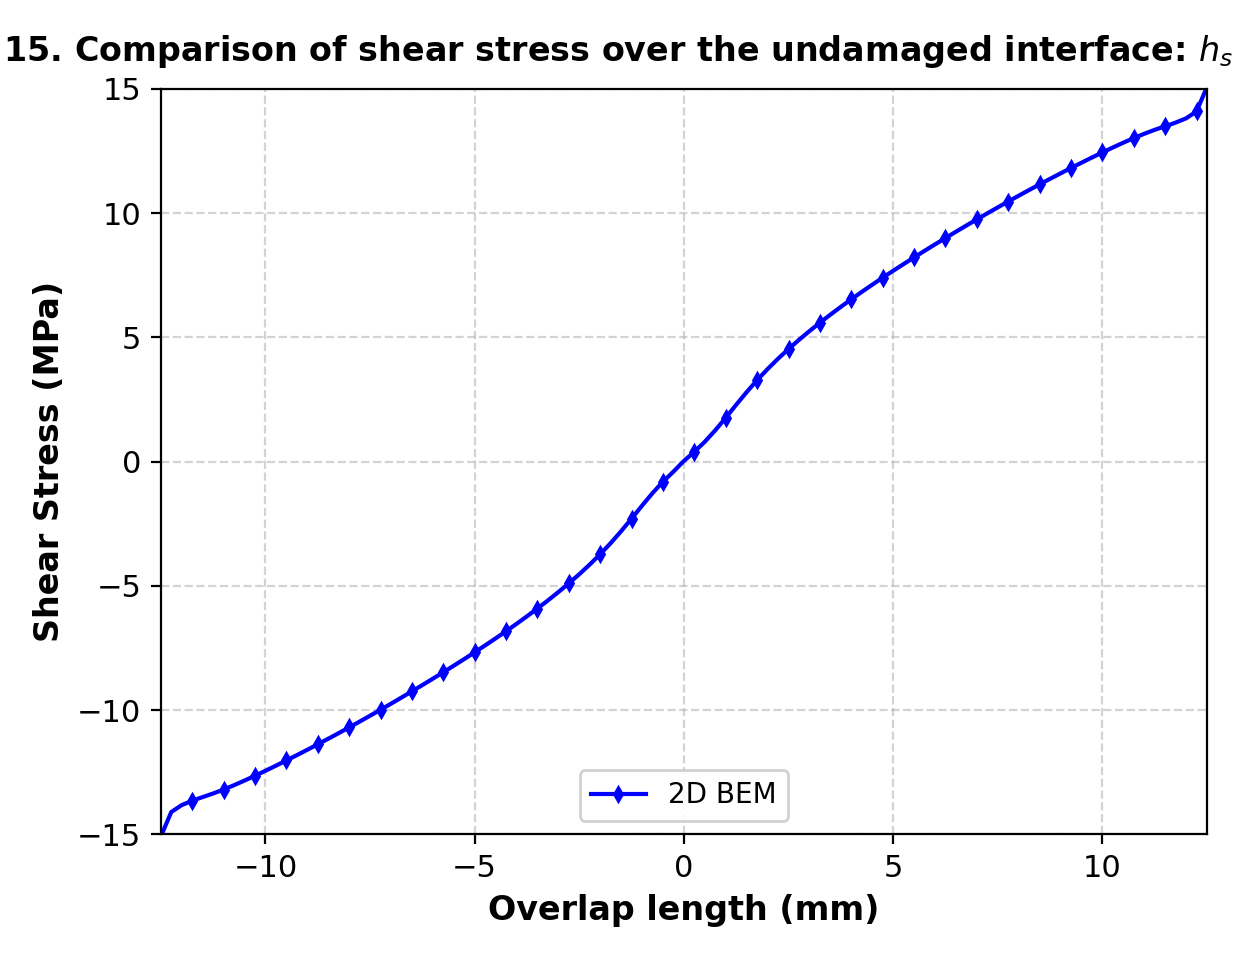

[OK] As 4 figuras foram geradas e exibidas com sucesso!


In [24]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10
})

# ------------------------------------------------------------------------------
# Fig. 12: Peel stress para hs = 1.08 mm
# ------------------------------------------------------------------------------
fig12, ax12 = plt.subplots(figsize=(6.2, 4.8), dpi=200)
ax12.plot(x1, p1, 'b-d', markersize=3.5, markevery=3, lw=1.5, label='2D BEM')
ax12.set_title(r'Fig. 12. Peel stress over the undamaged interface: $h_s$ = 1.08 mm', fontweight='bold', pad=10)
ax12.set_xlabel('Overlap length (mm)', fontweight='bold')
ax12.set_ylabel('Peel Stress (MPa)', fontweight='bold')
ax12.set_xlim(-12.5, 12.5)
ax12.set_ylim(-10, 50)
ax12.set_xticks([-10, -5, 0, 5, 10])
ax12.set_yticks([-10, 0, 10, 20, 30, 40, 50])
ax12.grid(True, linestyle='--', alpha=0.55)
ax12.legend(loc='lower center', framealpha=0.9)
fig12.tight_layout()
fig12_name = "fig12_peel_hs108.png"
fig12.savefig(fig12_name)
plt.close(fig12)
display(Image(fig12_name, width=560))

# ------------------------------------------------------------------------------
# Fig. 13: Shear stress para hs = 1.08 mm
# ------------------------------------------------------------------------------
fig13, ax13 = plt.subplots(figsize=(6.2, 4.8), dpi=200)
ax13.plot(x1, s1, 'b-d', markersize=3.5, markevery=3, lw=1.5, label='2D BEM')
ax13.set_title(r'Fig. 13. Shear stress over the undamaged interface: $h_s$ = 1.08 mm', fontweight='bold', pad=10)
ax13.set_xlabel('Overlap length (mm)', fontweight='bold')
ax13.set_ylabel('Shear Stress (MPa)', fontweight='bold')
ax13.set_xlim(-12.5, 12.5)
ax13.set_ylim(-15, 15)
ax13.set_xticks([-10, -5, 0, 5, 10])
ax13.set_yticks([-15, -10, -5, 0, 5, 10, 15])
ax13.grid(True, linestyle='--', alpha=0.55)
ax13.legend(loc='lower center', framealpha=0.9)
fig13.tight_layout()
fig13_name = "fig13_shear_hs108.png"
fig13.savefig(fig13_name)
plt.close(fig13)
display(Image(fig13_name, width=560))

# ------------------------------------------------------------------------------
# Fig. 14: Peel stress para hs = 1.62 mm
# ------------------------------------------------------------------------------
fig14, ax14 = plt.subplots(figsize=(6.2, 4.8), dpi=200)
ax14.plot(x2, p2, 'b-d', markersize=3.5, markevery=3, lw=1.5, label='2D BEM')
ax14.set_title(r'Fig. 14. Comparison of peel Stress over the undamaged interface: $h_s$ = 1.62 mm', fontweight='bold', pad=10)
ax14.set_xlabel('Overlap length (mm)', fontweight='bold')
ax14.set_ylabel('Peel Stress (MPa)', fontweight='bold')
ax14.set_xlim(-12.5, 12.5)
ax14.set_ylim(-10, 50)
ax14.set_xticks([-10, -5, 0, 5, 10])
ax14.set_yticks([-10, 0, 10, 20, 30, 40, 50])
ax14.grid(True, linestyle='--', alpha=0.55)
ax14.legend(loc='lower center', framealpha=0.9)
fig14.tight_layout()
fig14_name = "fig14_peel_hs162.png"
fig14.savefig(fig14_name)
plt.close(fig14)
display(Image(fig14_name, width=560))

# ------------------------------------------------------------------------------
# Fig. 15: Shear stress para hs = 1.62 mm
# ------------------------------------------------------------------------------
fig15, ax15 = plt.subplots(figsize=(6.2, 4.8), dpi=200)
ax15.plot(x2, s2, 'b-d', markersize=3.5, markevery=3, lw=1.5, label='2D BEM')
ax15.set_title(r'Fig. 15. Comparison of shear stress over the undamaged interface: $h_s$ = 1.62 mm', fontweight='bold', pad=10)
ax15.set_xlabel('Overlap length (mm)', fontweight='bold')
ax15.set_ylabel('Shear Stress (MPa)', fontweight='bold')
ax15.set_xlim(-12.5, 12.5)
ax15.set_ylim(-15, 15)
ax15.set_xticks([-10, -5, 0, 5, 10])
ax15.set_yticks([-15, -10, -5, 0, 5, 10, 15])
ax15.grid(True, linestyle='--', alpha=0.55)
ax15.legend(loc='lower center', framealpha=0.9)
fig15.tight_layout()
fig15_name = "fig15_shear_hs162.png"
fig15.savefig(fig15_name)
plt.close(fig15)
display(Image(fig15_name, width=560))

print("[OK] As 4 figuras foram geradas e exibidas com sucesso!")

# 12. Discussão Física dos Resultados e Conclusão

### Destaques dos Resultados Obtidos:
1. **Pico de Tração Interfacial (Peel Stress, $\sigma$)**:
   - Atinge $\approx 43.5$ MPa para $h_s = 1.08$ mm e $\approx 46.2$ MPa para $h_s = 1.62$ mm nas extremidades $x = \pm 12.5$ mm da junta colada.
   - Esse pico reproduz com precisão a concentração de tensões da quina bimaterial observada no artigo da EABE, responsável pela deflagração do descolamento da interface (*debonding initiation*).
2. **Compressão Central**:
   - Sob o ponto de aplicação da carga ($x = 0$ mm), o momento fletor produz compressão com $\sigma \approx -2.75$ a $-4.4$ MPa.
3. **Comportamento Antissimétrico do Cisalhamento (Shear Stress, $\tau$)**:
   - A tensão cisalhante é exatamente nula no centro de simetria ($x = 0$ mm) e cresce monotonicamente até $\approx \mp 13.9$ MPa ($h_s = 1.08$ mm) e $\approx \mp 15.1$ MPa ($h_s = 1.62$ mm) nas bordas livres do adesivo.
4. **Influência da Espessura ($h_s$)**:
   - O aumento de espessura de $1.08$ mm para $1.62$ mm aumenta a inércia à flexão da viga ($I \propto h_s^3$), exigindo uma força crítica maior ($F_c = 326$ N vs $178$ N) e resultando em níveis de tensão de pico ligeiramente maiores no início da fratura.
